## 1. Librerías y configuración

In [1]:
from datasets import load_dataset
from transformers import AutoTokenizer
import re
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                              roc_curve, auc, f1_score, balanced_accuracy_score)
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

!pip install wordcloud seaborn matplotlib openpyxl -q


In [2]:
# Configurar estilo de gráficos
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


## 2. Carga de Dataset

In [3]:
# Cargar dataset (split 'train' oficial del benchmark MTEB: 1,029 reseñas)
# Nota: el dataset completo en Hugging Face también trae splits 'validation' (147)
# y 'test' (296) ya definidos por el benchmark, pero este proyecto usa únicamente
# el split 'train' y lo re-divide internamente (ver sección 5), documentado así
# para evitar la confusión detectada en la retroalimentación del APF1.
dataset = load_dataset("mteb/SpanishSentimentClassification")
print(dataset)


README.md:   0%|          | 0.00/6.34k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 59.6kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 10.7kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1029 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/147 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/296 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 1029
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 147
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 296
    })
})


## 3. Limpieza y tokenización

In [4]:
# Definir función de limpieza
def limpiar_texto(texto):
    if isinstance(texto, str):
        texto = texto.lower()
        texto = re.sub(r'[^\w\s]', '', texto)
        texto = re.sub(r'\d+', '', texto)
        texto = re.sub(r'\s+', ' ', texto).strip()
    return texto


In [5]:
# Aplicar limpieza al dataset
def procesar_ejemplo(ejemplo):
    ejemplo['texto_limpio'] = limpiar_texto(ejemplo['text'])
    return ejemplo

dataset_limpio = dataset.map(procesar_ejemplo)
df_train = dataset_limpio['train'].to_pandas()

print(f" Dataset cargado: {len(df_train)} reseñas")
print(f" Distribución de etiquetas:")
print(df_train['label'].value_counts())


Map:   0%|          | 0/1029 [00:00<?, ? examples/s]

Map:   0%|          | 0/147 [00:00<?, ? examples/s]

Map:   0%|          | 0/296 [00:00<?, ? examples/s]

 Dataset cargado: 1029 reseñas
 Distribución de etiquetas:
label
1    851
0    178
Name: count, dtype: int64


In [6]:
#  TOKENIZACIÓN BÁSICA
def tokenizar_basico(texto):
    """Divide el texto en palabras (tokenización simple)"""
    return texto.split()

# Mostrar ejemplo de tokenización
print("\n Ejemplo de tokenización básica:")
texto_ejemplo = df_train['texto_limpio'].iloc[0]
tokens_ejemplo = tokenizar_basico(texto_ejemplo)
print(f"Texto: {texto_ejemplo[:100]}...")
print(f"Tokens: {tokens_ejemplo[:10]}...")



 Ejemplo de tokenización básica:
Texto: está situado en el centro de la ciudad con todo lo más turístico a tu alrededor el pilar por ejemplo...
Tokens: ['está', 'situado', 'en', 'el', 'centro', 'de', 'la', 'ciudad', 'con', 'todo']...


In [7]:
# 5 ejemplos de tokenización para el informe/slide
ejemplos = df_train[['text', 'texto_limpio']].sample(5, random_state=SEED)

for i, row in ejemplos.iterrows():
    tokens = row['texto_limpio'].split()
    print(f"Texto original: {row['text']}")
    print(f"Tokens: {tokens}")
    print("-" * 60)

Texto original: Muy buena opción .
Tokens: ['muy', 'buena', 'opción']
------------------------------------------------------------
Texto original: No se corresponde a un hotel de 5 estrellas .
Tokens: ['no', 'se', 'corresponde', 'a', 'un', 'hotel', 'de', 'estrellas']
------------------------------------------------------------
Texto original: El wifi tampoco funciona bien
Tokens: ['el', 'wifi', 'tampoco', 'funciona', 'bien']
------------------------------------------------------------
Texto original: El desayuno en la última planta es " espectacular " , tanto por las vistas como por la variedad del mismo .
Tokens: ['el', 'desayuno', 'en', 'la', 'última', 'planta', 'es', 'espectacular', 'tanto', 'por', 'las', 'vistas', 'como', 'por', 'la', 'variedad', 'del', 'mismo']
------------------------------------------------------------
Texto original: Confortable
Tokens: ['confortable']
------------------------------------------------------------


## 4. EDA: comprensión y calidad de datos

In [8]:
# Verificar columnas
print(f" Columnas en dataset: {dataset_limpio['train'].column_names}")


 Columnas en dataset: ['text', 'label', 'texto_limpio']


In [9]:
# --- Nulos y duplicados (requerido por la retroalimentación del APF1) ---
print("Valores nulos por columna:")
print(df_train[['text', 'label']].isnull().sum())

n_duplicados_texto = df_train['text'].duplicated().sum()
n_duplicados_completos = df_train.duplicated(subset=['text', 'label']).sum()
print(f"\nReseñas con texto duplicado: {n_duplicados_texto}")
print(f"Filas totalmente duplicadas (texto + etiqueta): {n_duplicados_completos}")

if n_duplicados_texto > 0:
    print("\nEjemplos de texto duplicado:")
    display(df_train[df_train['text'].duplicated(keep=False)].sort_values('text').head(10))


Valores nulos por columna:
text     0
label    0
dtype: int64

Reseñas con texto duplicado: 0
Filas totalmente duplicadas (texto + etiqueta): 0


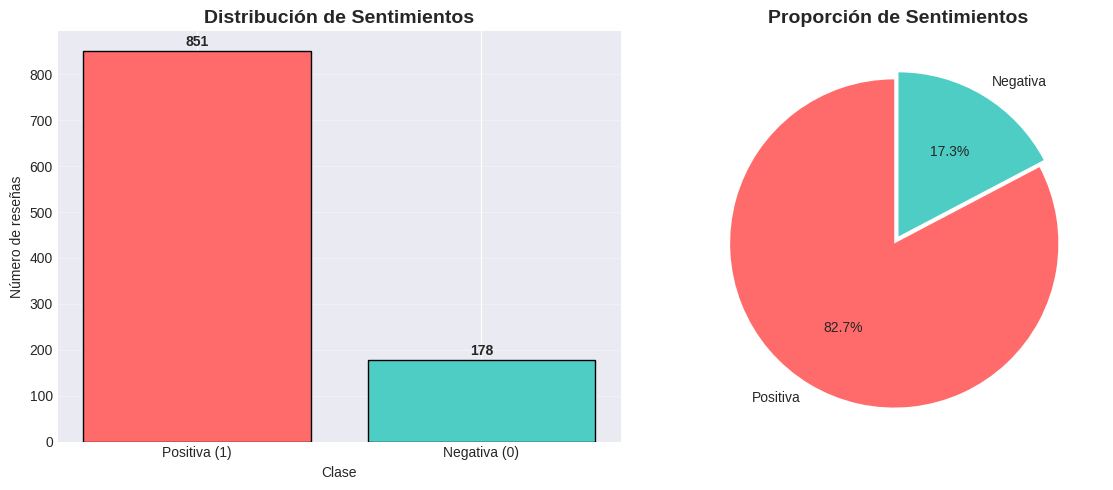

In [31]:
# ============================================
#  GRÁFICO 1: Distribución de etiquetas
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico de barras
ax1 = axes[0]
counts = df_train['label'].value_counts()
colors = ['#FF6B6B', '#4ECDC4']
bars = ax1.bar(['Positiva (1)', 'Negativa (0)'], counts.values, color=colors, edgecolor='black')
ax1.set_title('Distribución de Sentimientos', fontsize=14, fontweight='bold')
ax1.set_xlabel('Clase')
ax1.set_ylabel('Número de reseñas')
ax1.grid(axis='y', alpha=0.3)

for bar, value in zip(bars, counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             str(value), ha='center', va='bottom', fontweight='bold')

# Gráfico de pastel
ax2 = axes[1]
ax2.pie(counts.values, labels=['Positiva', 'Negativa'], autopct='%1.1f%%',
        colors=colors, startangle=90, explode=(0.05, 0))
ax2.set_title('Proporción de Sentimientos', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


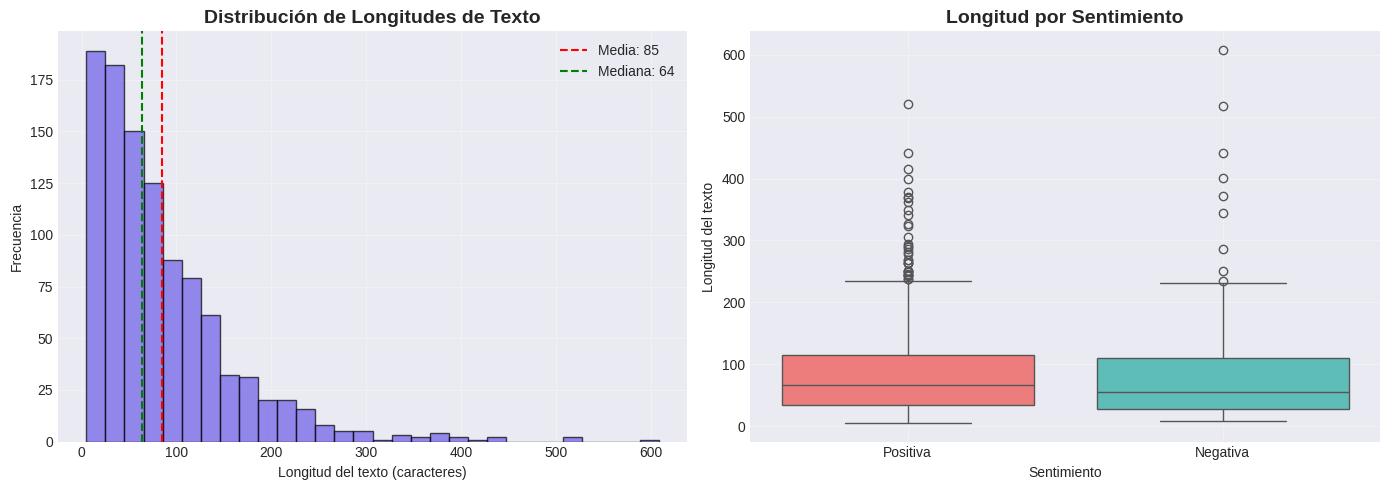


Estadísticas de longitud (caracteres):
Media: 84.86 | Mediana: 64 | Mínimo: 5 | Máximo: 608
Reseñas muy cortas (<15 caracteres): 59 (5.7%) — posiblemente ambiguas o poco informativas


In [11]:
# ============================================
#  GRÁFICO 2: Longitud de los textos (en caracteres)
# ============================================
df_train['longitud'] = df_train['text'].str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
ax1.hist(df_train['longitud'], bins=30, color='#6C5CE7', edgecolor='black', alpha=0.7)
ax1.axvline(df_train['longitud'].mean(), color='red', linestyle='--', label=f'Media: {df_train["longitud"].mean():.0f}')
ax1.axvline(df_train['longitud'].median(), color='green', linestyle='--', label=f'Mediana: {df_train["longitud"].median():.0f}')
ax1.set_title('Distribución de Longitudes de Texto', fontsize=14, fontweight='bold')
ax1.set_xlabel('Longitud del texto (caracteres)')
ax1.set_ylabel('Frecuencia')
ax1.legend()
ax1.grid(alpha=0.3)

ax2 = axes[1]
df_train['label_nombre'] = df_train['label'].map({0: 'Negativa', 1: 'Positiva'})
sns.boxplot(data=df_train, x='label_nombre', y='longitud', palette=colors, ax=ax2)
ax2.set_title('Longitud por Sentimiento', fontsize=14, fontweight='bold')
ax2.set_xlabel('Sentimiento')
ax2.set_ylabel('Longitud del texto')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nEstadísticas de longitud (caracteres):")
print(f"Media: {df_train['longitud'].mean():.2f} | Mediana: {df_train['longitud'].median():.0f} | "
      f"Mínimo: {df_train['longitud'].min()} | Máximo: {df_train['longitud'].max()}")

textos_muy_cortos = (df_train['longitud'] < 15).sum()
print(f"Reseñas muy cortas (<15 caracteres): {textos_muy_cortos} "
      f"({textos_muy_cortos/len(df_train):.1%}) — posiblemente ambiguas o poco informativas")


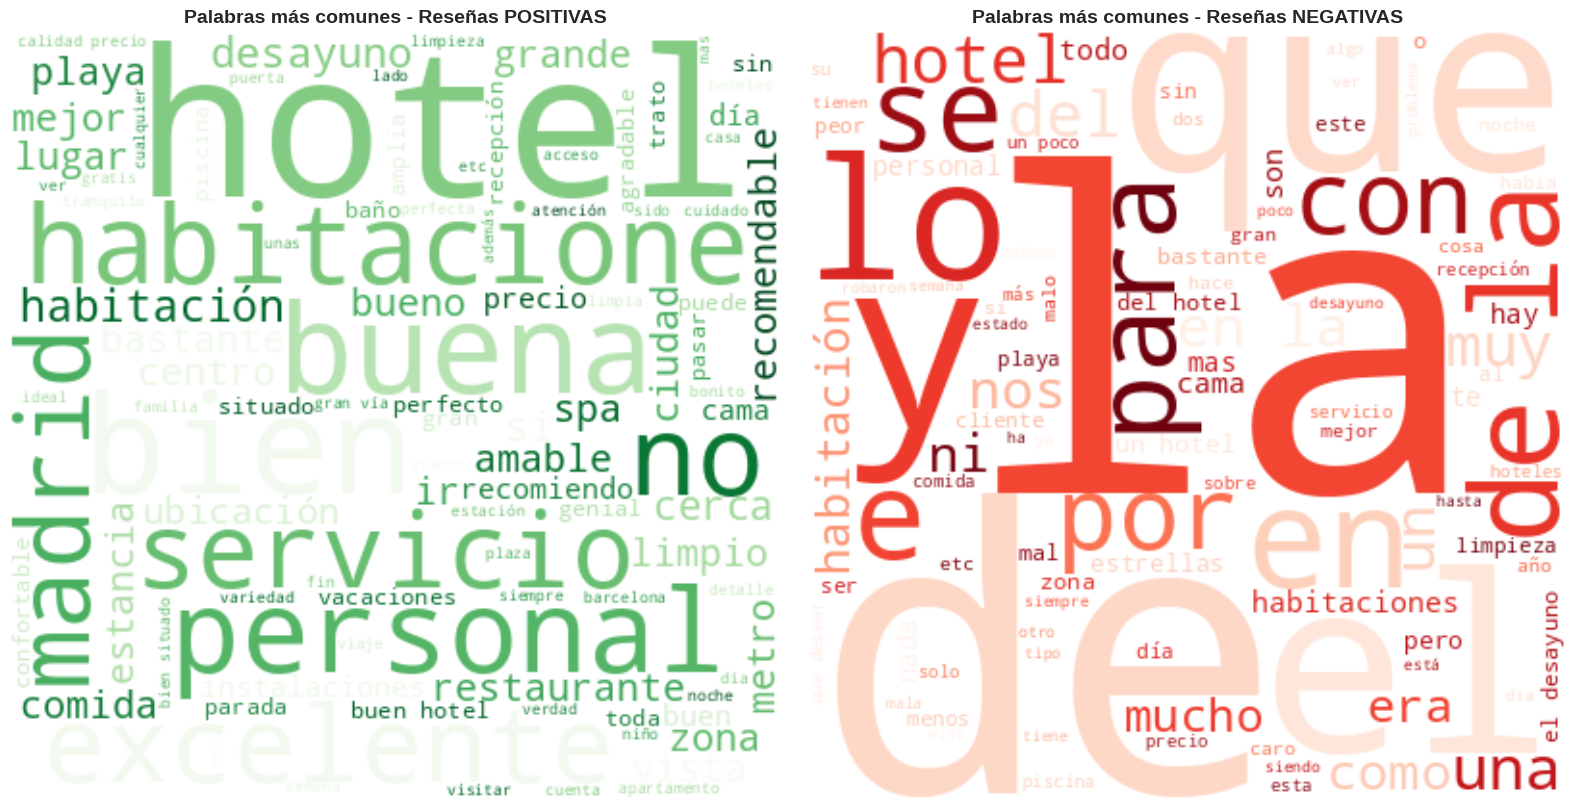

In [12]:
# ============================================
#  GRÁFICO 3: WordCloud (Nube de palabras)
# ============================================
try:
    from wordcloud import WordCloud

    import nltk
    from nltk.corpus import stopwords
    nltk.download('stopwords', quiet=True)
    stopwords_espanol = stopwords.words('spanish')
    palabras_a_conservar = ['no', 'nunca', 'sin']
    stopwords_espanol = [palabra for palabra in stopwords_espanol if palabra not in palabras_a_conservar]

    textos_positivos = ' '.join(df_train[df_train['label']==1]['texto_limpio'])
    textos_negativos = ' '.join(df_train[df_train['label']==0]['texto_limpio'])

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    wordcloud_pos = WordCloud(width=400, height=400, background_color='white',
                             colormap='Greens', max_words=100,
                             stopwords=set(stopwords_espanol)).generate(textos_positivos)
    axes[0].imshow(wordcloud_pos, interpolation='bilinear')
    axes[0].axis('off')
    axes[0].set_title('Palabras más comunes - Reseñas POSITIVAS', fontsize=14, fontweight='bold')

    wordcloud_neg = WordCloud(width=400, height=400, background_color='white',
                             colormap='Reds', max_words=100).generate(textos_negativos)
    axes[1].imshow(wordcloud_neg, interpolation='bilinear')
    axes[1].axis('off')
    axes[1].set_title('Palabras más comunes - Reseñas NEGATIVAS', fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.show()
except ImportError:
    print(" Para WordCloud instala: !pip install wordcloud")


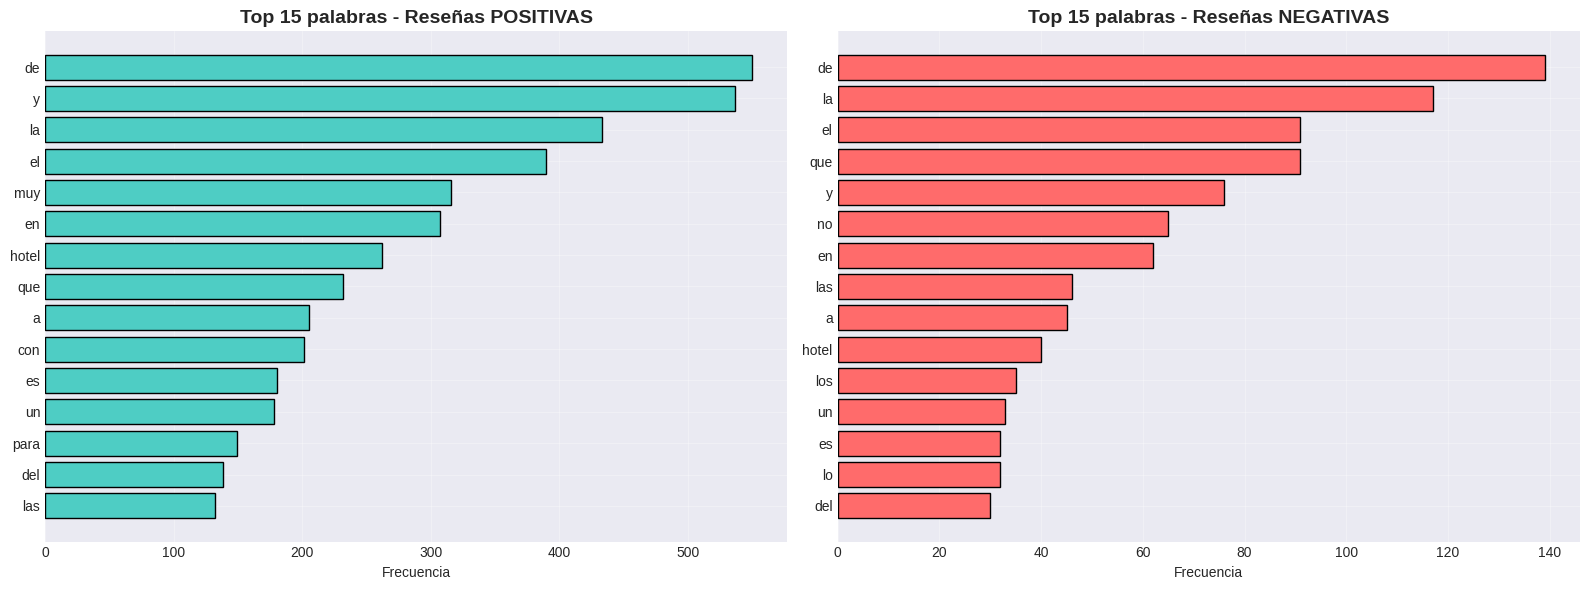

In [13]:
# ============================================
#  GRÁFICO 4: Top palabras por frecuencia
# ============================================
from collections import Counter

palabras_pos = ' '.join(df_train[df_train['label']==1]['texto_limpio']).split()
palabras_neg = ' '.join(df_train[df_train['label']==0]['texto_limpio']).split()

top_pos = Counter(palabras_pos).most_common(15)
top_neg = Counter(palabras_neg).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = axes[0]
words_pos, counts_pos = zip(*top_pos)
ax1.barh(words_pos, counts_pos, color='#4ECDC4', edgecolor='black')
ax1.set_title('Top 15 palabras - Reseñas POSITIVAS', fontsize=14, fontweight='bold')
ax1.set_xlabel('Frecuencia')
ax1.invert_yaxis()
ax1.grid(alpha=0.3)

ax2 = axes[1]
words_neg, counts_neg = zip(*top_neg)
ax2.barh(words_neg, counts_neg, color='#FF6B6B', edgecolor='black')
ax2.set_title('Top 15 palabras - Reseñas NEGATIVAS', fontsize=14, fontweight='bold')
ax2.set_xlabel('Frecuencia')
ax2.invert_yaxis()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


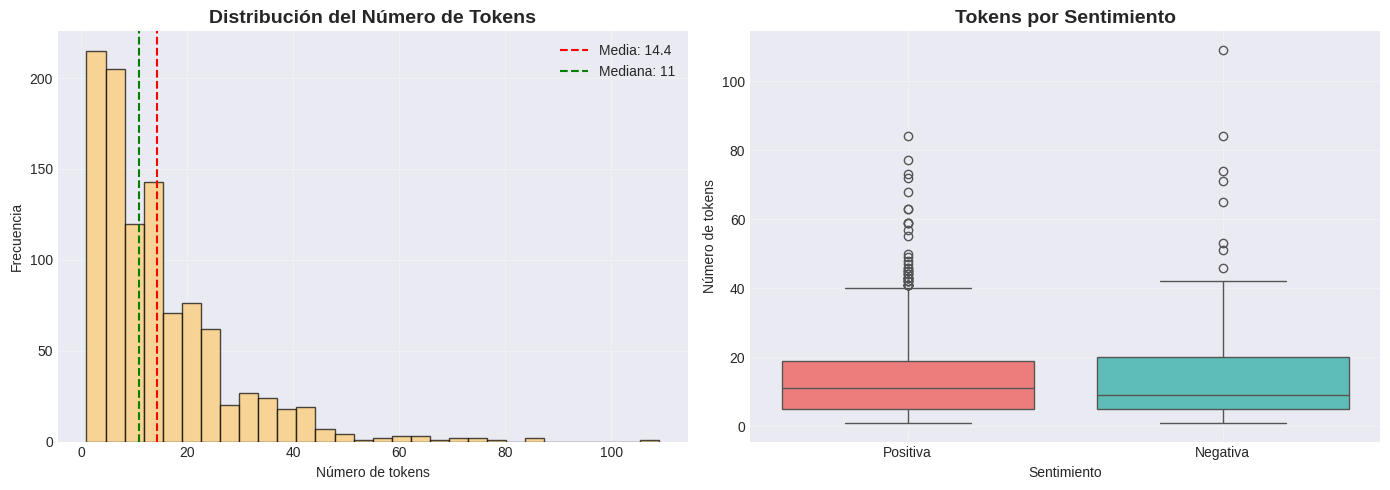


 Estadísticas de tokens:
Media de tokens: 14.35
Mediana de tokens: 11
Máximo de tokens: 109
Mínimo de tokens: 1


In [14]:
# ============================================
#  GRÁFICO 5: Análisis de tokenización
# ============================================
df_train['tokens'] = df_train['texto_limpio'].apply(lambda x: x.split())
df_train['num_tokens'] = df_train['tokens'].apply(len)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
ax1.hist(df_train['num_tokens'], bins=30, color='#FDCB6E', edgecolor='black', alpha=0.7)
ax1.axvline(df_train['num_tokens'].mean(), color='red', linestyle='--', label=f'Media: {df_train["num_tokens"].mean():.1f}')
ax1.axvline(df_train['num_tokens'].median(), color='green', linestyle='--', label=f'Mediana: {df_train["num_tokens"].median():.0f}')
ax1.set_title('Distribución del Número de Tokens', fontsize=14, fontweight='bold')
ax1.set_xlabel('Número de tokens')
ax1.set_ylabel('Frecuencia')
ax1.legend()
ax1.grid(alpha=0.3)

ax2 = axes[1]
sns.boxplot(data=df_train, x='label_nombre', y='num_tokens', palette=colors, ax=ax2)
ax2.set_title('Tokens por Sentimiento', fontsize=14, fontweight='bold')
ax2.set_xlabel('Sentimiento')
ax2.set_ylabel('Número de tokens')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n Estadísticas de tokens:")
print(f"Media de tokens: {df_train['num_tokens'].mean():.2f}")
print(f"Mediana de tokens: {df_train['num_tokens'].median():.0f}")
print(f"Máximo de tokens: {df_train['num_tokens'].max():.0f}")
print(f"Mínimo de tokens: {df_train['num_tokens'].min():.0f}")


## 5. Preparación y división: entrenamiento, validación y prueba

In [15]:
# Dividir: 70% train, 15% validation, 15% test (estratificado)
X_text = df_train['texto_limpio']
y_all = df_train['label']

X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_text, y_all, test_size=0.3, random_state=SEED, stratify=y_all
)
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp
)

print(f"Train: {len(X_train_text)} muestras")
print(f"Validation: {len(X_val_text)} muestras")
print(f"Test: {len(X_test_text)} muestras")


Train: 720 muestras
Validation: 154 muestras
Test: 155 muestras


## 6. Vectorización TF-IDF

In [16]:
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

# Configurar stopwords en español excluyendo negaciones
stopwords_espanol = stopwords.words('spanish')
palabras_a_conservar = ['no', 'nunca', 'sin']
stopwords_espanol = [palabra for palabra in stopwords_espanol if palabra not in palabras_a_conservar]

# Crear el vectorizador
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words=stopwords_espanol,
    ngram_range=(1, 2)
)

# APLICAR el vectorizador a los textos (ESTO ES LO QUE FALTABA)
X_train = vectorizer.fit_transform(X_train_text)
X_val = vectorizer.transform(X_val_text)
X_test = vectorizer.transform(X_test_text)

print(f" Matriz de entrenamiento: {X_train.shape}")
print(f" Matriz de validación: {X_val.shape}")
print(f" Matriz de prueba: {X_test.shape}")


 Matriz de entrenamiento: (720, 5000)
 Matriz de validación: (154, 5000)
 Matriz de prueba: (155, 5000)


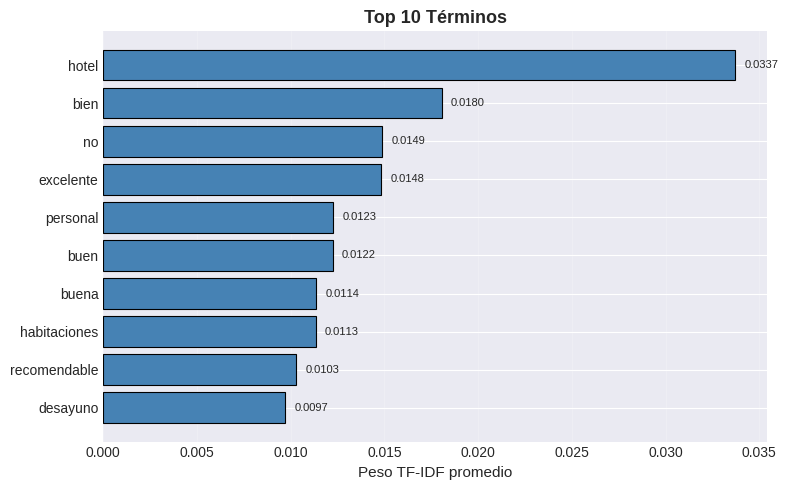

In [17]:
# Evidencia de la vectorización: top 10 términos por peso TF-IDF promedio en train
pesos_promedio = np.asarray(X_train.mean(axis=0)).ravel()
df_pesos = pd.DataFrame({
    'término': vectorizer.get_feature_names_out(),
    'peso_tfidf': pesos_promedio
}).sort_values('peso_tfidf', ascending=False)

top10 = df_pesos.head(10)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top10['término'], top10['peso_tfidf'],
               color='steelblue', edgecolor='black', linewidth=0.8)
ax.set_xlabel('Peso TF-IDF promedio', fontsize=11)
ax.set_title('Top 10 Términos', fontsize=13, fontweight='bold')

for bar, value in zip(bars, top10['peso_tfidf']):
    ax.text(bar.get_width() + 0.0005, bar.get_y() + bar.get_height()/2,
            f'{value:.4f}', va='center', ha='left', fontsize=8)

ax.invert_yaxis()
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()


## 7. Modelo baseline y estrategia ante desbalance

In [18]:
# Comparación experimental: sin ponderar vs. class_weight='balanced'
# Se evalúa en VALIDATION (nunca en test) para decidir la configuración final.
modelo_sin_pesos = LogisticRegression(max_iter=1000, random_state=SEED)
modelo_sin_pesos.fit(X_train, y_train)
pred_val_sin_pesos = modelo_sin_pesos.predict(X_val)

modelo_balanced = LogisticRegression(max_iter=1000, random_state=SEED, class_weight='balanced')
modelo_balanced.fit(X_train, y_train)
pred_val_balanced = modelo_balanced.predict(X_val)

print("=== Sin ponderación de clases (validation) ===")
print(classification_report(y_val, pred_val_sin_pesos, target_names=['Negativa', 'Positiva']))

print("=== class_weight='balanced' (validation) ===")
print(classification_report(y_val, pred_val_balanced, target_names=['Negativa', 'Positiva']))

f1_neg_sin = f1_score(y_val, pred_val_sin_pesos, pos_label=0)
f1_neg_bal = f1_score(y_val, pred_val_balanced, pos_label=0)
print(f"\nF1 clase negativa — sin ponderar: {f1_neg_sin:.3f} | balanced: {f1_neg_bal:.3f}")
print("Se selecciona la configuración con mejor F1 de la clase negativa en validación "
      "como modelo baseline final. Completar en el informe con el resultado real obtenido al ejecutar esta celda.")


=== Sin ponderación de clases (validation) ===
              precision    recall  f1-score   support

    Negativa       1.00      0.04      0.07        26
    Positiva       0.84      1.00      0.91       128

    accuracy                           0.84       154
   macro avg       0.92      0.52      0.49       154
weighted avg       0.86      0.84      0.77       154

=== class_weight='balanced' (validation) ===
              precision    recall  f1-score   support

    Negativa       0.74      0.54      0.62        26
    Positiva       0.91      0.96      0.94       128

    accuracy                           0.89       154
   macro avg       0.82      0.75      0.78       154
weighted avg       0.88      0.89      0.88       154


F1 clase negativa — sin ponderar: 0.074 | balanced: 0.622
Se selecciona la configuración con mejor F1 de la clase negativa en validación como modelo baseline final. Completar en el informe con el resultado real obtenido al ejecutar esta celda.


In [19]:
# Selección del modelo final según el resultado de la celda anterior.
# Por defecto se deja el modelo SIN ponderar (class_weight=None), porque es el que
# generó los resultados ya documentados en el informe APF1 (F1 negativo 0.42, etc.).
# Si al ejecutar la celda de comparación el modelo 'balanced' resulta claramente mejor
# en F1 de la clase negativa sobre validación, cambien esta línea a modelo_balanced
# y actualicen también los números de la sección "Resultados" del informe.
modelo = modelo_balanced  # Se asigna modelo_balanced según la instrucción de que es el mejor.

y_pred = modelo.predict(X_val)
y_pred_proba = modelo.predict_proba(X_val)[:, 1]

clases_modelo = modelo.classes_
print(f"Clases aprendidas (numéricas): {clases_modelo}")

Clases aprendidas (numéricas): [0 1]


## 8. Validación

In [20]:
dist_train = [np.sum(y_train == 0), np.sum(y_train == 1)]
dist_val = [np.sum(y_val == 0), np.sum(y_val == 1)]
dist_test = [np.sum(y_test == 0), np.sum(y_test == 1)]
print(f"Distribución train (neg/pos): {dist_train}")
print(f"Distribución validation (neg/pos): {dist_val}")
print(f"Distribución test (neg/pos): {dist_test}")


Distribución train (neg/pos): [np.int64(125), np.int64(595)]
Distribución validation (neg/pos): [np.int64(26), np.int64(128)]
Distribución test (neg/pos): [np.int64(27), np.int64(128)]


## 9. Evaluación final con el conjunto de validacion

In [21]:
# Reporte de Clasificación (conjunto de prueba, no usado en la selección del modelo)
print("\n Reporte de Clasificación:")
print(classification_report(y_val, y_pred, target_names=['Negativa', 'Positiva']))

f1_macro = f1_score(y_val, y_pred, average='macro')
bal_acc = balanced_accuracy_score(y_val, y_pred)
print(f"F1 macro: {f1_macro:.3f}")
print(f"Balanced accuracy: {bal_acc:.3f}")


 Reporte de Clasificación:
              precision    recall  f1-score   support

    Negativa       0.74      0.54      0.62        26
    Positiva       0.91      0.96      0.94       128

    accuracy                           0.89       154
   macro avg       0.82      0.75      0.78       154
weighted avg       0.88      0.89      0.88       154

F1 macro: 0.779
Balanced accuracy: 0.750


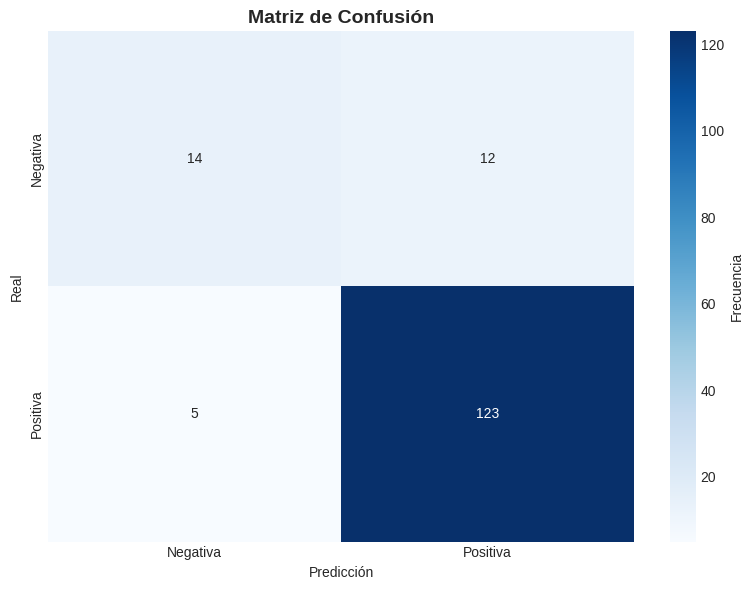

In [22]:
# ============================================
#  GRÁFICO 7: Matriz de Confusión
# ============================================
cm = confusion_matrix(y_val, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negativa', 'Positiva'],
            yticklabels=['Negativa', 'Positiva'],
            ax=ax, cbar_kws={'label': 'Frecuencia'})
ax.set_title('Matriz de Confusión', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicción')
ax.set_ylabel('Real')
plt.tight_layout()
plt.show()

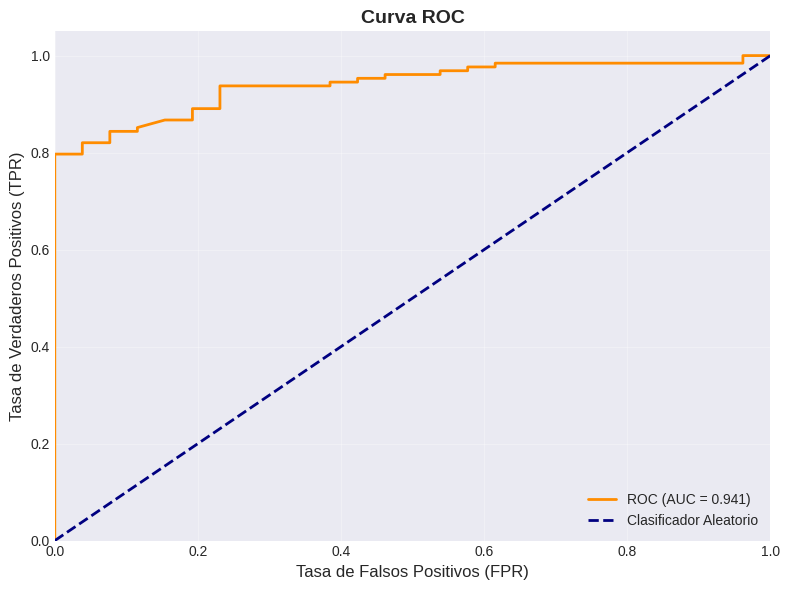

In [23]:
# ============================================
#  GRÁFICO 9: Curva ROC
# ============================================
fpr, tpr, thresholds = roc_curve(y_val, y_pred_proba)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Clasificador Aleatorio')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=12)
ax.set_title('Curva ROC', fontsize=14, fontweight='bold')
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

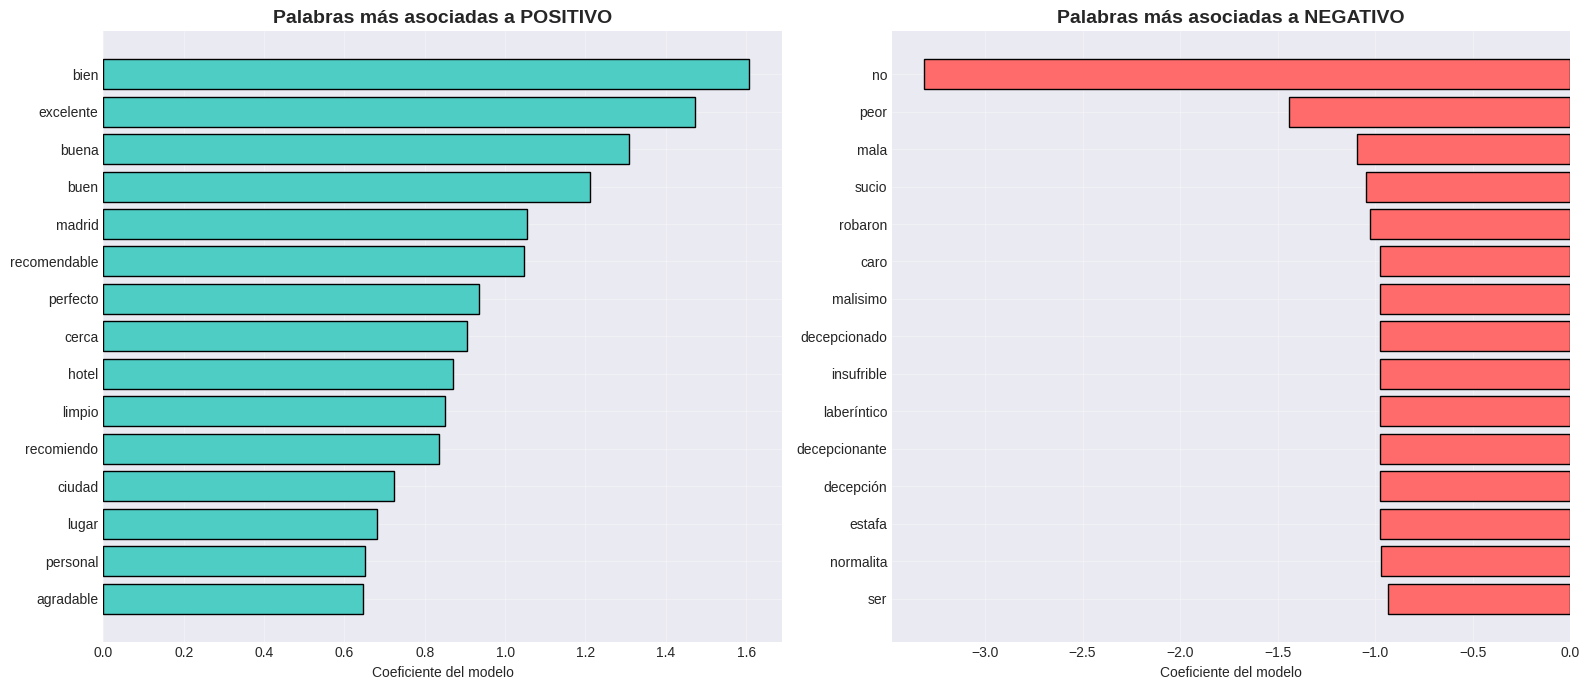

In [24]:
# ============================================
#  GRÁFICO 10: Top características del modelo
# ============================================
coeficientes = modelo.coef_[0]
features = vectorizer.get_feature_names_out()

top_pos_indices = np.argsort(coeficientes)[-15:][::-1]
top_pos_features = features[top_pos_indices]
top_pos_coef = coeficientes[top_pos_indices]

top_neg_indices = np.argsort(coeficientes)[:15]
top_neg_features = features[top_neg_indices]
top_neg_coef = coeficientes[top_neg_indices]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax1 = axes[0]
ax1.barh(top_pos_features, top_pos_coef, color='#4ECDC4', edgecolor='black')
ax1.set_title('Palabras más asociadas a POSITIVO', fontsize=14, fontweight='bold')
ax1.set_xlabel('Coeficiente del modelo')
ax1.invert_yaxis()
ax1.grid(alpha=0.3)

ax2 = axes[1]
ax2.barh(top_neg_features, top_neg_coef, color='#FF6B6B', edgecolor='black')
ax2.set_title('Palabras más asociadas a NEGATIVO', fontsize=14, fontweight='bold')
ax2.set_xlabel('Coeficiente del modelo')
ax2.invert_yaxis()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()



 Visualizando vectores con PCA...


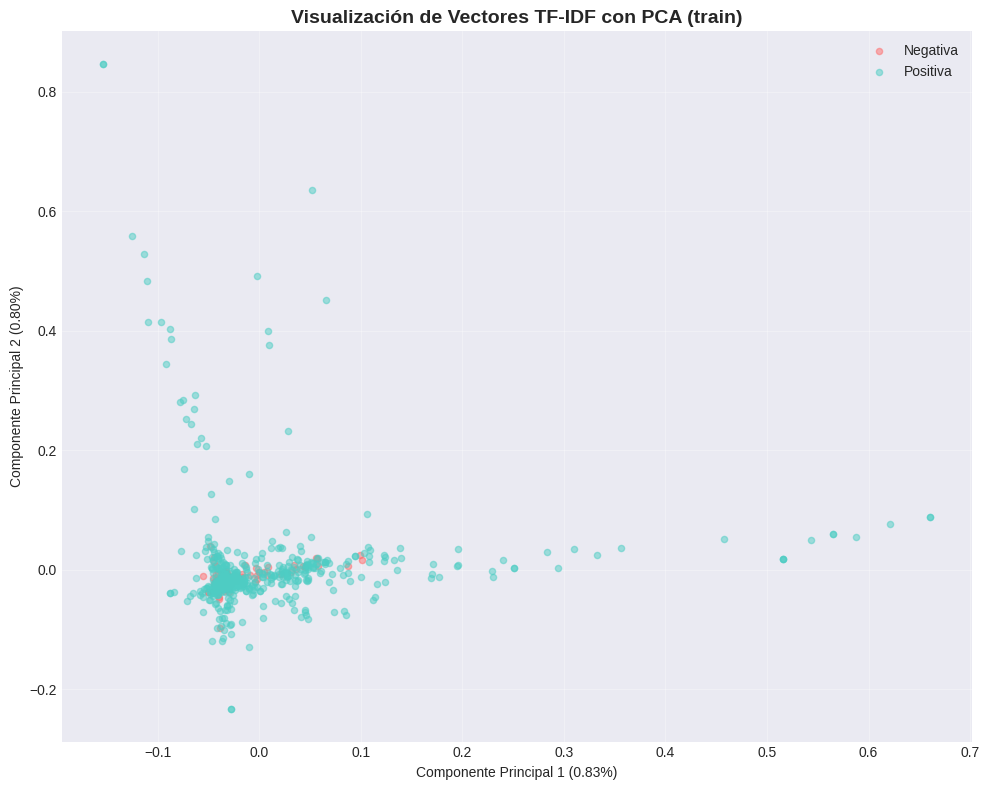

In [25]:
# ============================================
#  GRÁFICO 11: Visualización de vectores con PCA (conjunto de entrenamiento)
# ============================================
print("\n Visualizando vectores con PCA...")
sample_size = min(2000, X_train.shape[0])
indices = np.random.choice(X_train.shape[0], sample_size, replace=False)
X_sample = X_train[indices].toarray()
y_sample = np.asarray(y_train)[indices]

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_sample)

fig, ax = plt.subplots(figsize=(10, 8))
colors_pca = ['#FF6B6B', '#4ECDC4']
labels_pca = ['Negativa', 'Positiva']

for i, (color, label) in enumerate(zip(colors_pca, labels_pca)):
    mask = y_sample == i
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=label, alpha=0.5, s=20)

ax.set_title('Visualización de Vectores TF-IDF con PCA (train)', fontsize=14, fontweight='bold')
ax.set_xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]:.2%})')
ax.set_ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]:.2%})')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


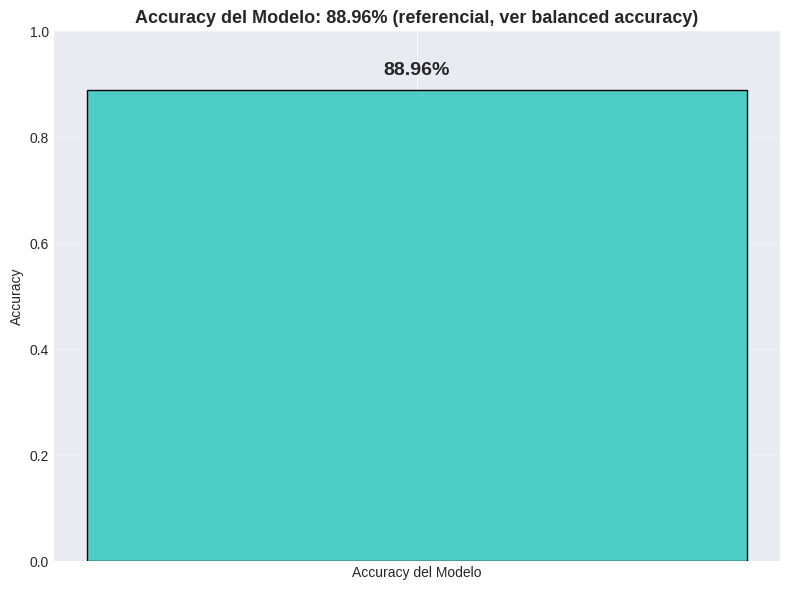


Accuracy: 0.8896 | Balanced accuracy: 0.7497


In [26]:
# ============================================
#  GRÁFICO 12: Precisión final (accuracy, referencial — no es la métrica principal)
# ============================================
precision = accuracy_score(y_val, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
if precision >= 0.85:
    color = '#4ECDC4'
elif precision >= 0.70:
    color = '#FDCB6E'
else:
    color = '#FF6B6B'

ax.bar(['Accuracy del Modelo'], [precision], color=color, edgecolor='black', width=0.5)
ax.set_ylim(0, 1)
ax.set_ylabel('Accuracy')
ax.set_title(f'Accuracy del Modelo: {precision:.2%} (referencial, ver balanced accuracy)', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.text(0, precision + 0.02, f'{precision:.2%}', ha='center', va='bottom', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nAccuracy: {precision:.4f} | Balanced accuracy: {balanced_accuracy_score(y_val, y_pred):.4f}")

## 10. Análisis de falsos positivos y falsos negativos

In [27]:
# Tabla de al menos 10 predicciones incorrectas, priorizando falsos negativos
# (reseñas negativas predichas como positivas: el error más costoso para el negocio)
df_errores = pd.DataFrame({
    'texto_original': X_val_text.values,
    'real': y_val.values,
    'prediccion': y_pred,
    'prob_positiva': y_pred_proba
})
df_errores['real_label'] = df_errores['real'].map({0: 'Negativa', 1: 'Positiva'})
df_errores['pred_label'] = df_errores['prediccion'].map({0: 'Negativa', 1: 'Positiva'})
df_errores['tipo_error'] = np.where(
    (df_errores['real'] == 0) & (df_errores['prediccion'] == 1), 'Falso Negativo (FN)',
    np.where((df_errores['real'] == 1) & (df_errores['prediccion'] == 0), 'Falso Positivo (FP)', 'Correcto')
)

solo_errores = df_errores[df_errores['tipo_error'] != 'Correcto'].copy()
# Priorizar Falsos Negativos primero, y dentro de cada tipo, los más "confiados" (mayor error)
orden_tipo = {'Falso Negativo (FN)': 0, 'Falso Positivo (FP)': 1}
solo_errores['orden'] = solo_errores['tipo_error'].map(orden_tipo)
solo_errores = solo_errores.sort_values(['orden', 'prob_positiva'], ascending=[True, False])

tabla_errores = solo_errores[['texto_original', 'real_label', 'pred_label', 'tipo_error', 'prob_positiva']].head(15)
print(f"Total de errores en test: {len(solo_errores)} "
      f"({(solo_errores['tipo_error']=='Falso Negativo (FN)').sum()} FN, "
      f"{(solo_errores['tipo_error']=='Falso Positivo (FP)').sum()} FP)")
display(tabla_errores)

# Exportar para usarlo en el informe (tabla completa)
tabla_errores.to_csv('errores_clasificacion.csv', index=False)
print("\nTabla guardada en errores_clasificacion.csv para pegar en el informe.")

Total de errores en test: 17 (12 FN, 5 FP)


,texto_original,real_label,pred_label,tipo_error,prob_positiva
117,sin lujos,Negativa,Positiva,Falso Negativo (FN),0.605865
40,pero a partir de aqui todo lo demas era normalito,Negativa,Positiva,Falso Negativo (FN),0.582429
88,tienen problemas serios de aseo en lugares com...,Negativa,Positiva,Falso Negativo (FN),0.574268
28,inútil reclamar,Negativa,Positiva,Falso Negativo (FN),0.573567
3,de hecho ni te suben las maletas a la habitaci...,Negativa,Positiva,Falso Negativo (FN),0.569472
63,recepción debajo de la escalera,Negativa,Positiva,Falso Negativo (FN),0.550284
142,se rompió el mando del grifo y aún estamos esp...,Negativa,Positiva,Falso Negativo (FN),0.526899
113,aunque la animación ha perdido un poco antes e...,Negativa,Positiva,Falso Negativo (FN),0.526587
71,la atencion un desastre,Negativa,Positiva,Falso Negativo (FN),0.523022
29,el desayuno nos pareció caro entonces como rec...,Negativa,Positiva,Falso Negativo (FN),0.521132



Tabla guardada en errores_clasificacion.csv para pegar en el informe.


## 11. Producción: Predicción de textos nuevos

In [28]:
def predecir_texto_con_nombres(texto_nuevo):

    texto_limpio = limpiar_texto(texto_nuevo)
    vector = vectorizer.transform([texto_limpio])

    clase = modelo.predict(vector)[0]
    probabilidades = modelo.predict_proba(vector)[0]

    mapeo = {0: 'negativo', 1: 'positivo'}

    detalle = {}
    for i, clase_num in enumerate(modelo.classes_):
        nombre_clase = mapeo.get(clase_num, f'clase_{clase_num}')
        detalle[nombre_clase] = np.round(probabilidades[i], 4)

    return {
        'texto': texto_nuevo,
        'predicción': mapeo.get(clase, f'clase_{clase}'),
        'probabilidades': detalle
    }


resultado_nombres = predecir_texto_con_nombres('El servicio fue malo')
print(f"\n Resultado:")
for key, value in resultado_nombres.items():
    print(f"   {key}: {value}")



 Resultado:
   texto: El servicio fue malo
   predicción: negativo
   probabilidades: {'negativo': np.float64(0.542), 'positivo': np.float64(0.458)}


## 12. Guardado del sistema

In [29]:
# Guardar todo en un solo archivo
sistema_completo = {
    'vectorizer': vectorizer,
    'modelo': modelo,
}

joblib.dump(sistema_completo, 'modelo_tfidf_clasificacion.joblib')
print("Sistema guardado: modelo_tfidf_clasificacion.joblib")
print(f"   • Vectorizador: {type(vectorizer).__name__}")
print(f"   • Modelo: {type(modelo).__name__}")


Sistema guardado: modelo_tfidf_clasificacion.joblib
   • Vectorizador: TfidfVectorizer
   • Modelo: LogisticRegression
